In [1]:
##################################################################################
# # ! TMI anomalies of an induced dipole source at 12 places of interest (POIs)
# # ! around the world: same |m|, magnetization parallel to the local main field
##################################################################################
# %%
# # ! Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 300
from magnetic_forward_numba import dipole_tmi

In [2]:
# # ! Places of interest (POIs)
# Recorded main-field directions from IGRF-13 (epoch 2025-01-01):
# name: (latitude [deg], longitude [deg], declination D [deg], inclination I [deg])
POIS = {
    'Tromso, Norway':         ( 69.65,   18.96,  10.90,  78.45),
    'Moscow, Russia':         ( 55.76,   37.62,  12.09,  71.76),
    'London, UK':             ( 51.51,   -0.13,   1.03,  66.49),
    'New York, USA':          ( 40.71,  -74.01, -12.50,  65.68),
    'Beijing, China':         ( 39.90,  116.41,  -7.69,  59.29),
    'Tokyo, Japan':           ( 35.68,  139.69,  -7.91,  49.48),
    'Hangzhou, China':        ( 30.27,  120.16,  -6.20,  46.16),
    'Guangzhou, China':       ( 23.13,  113.26,  -3.47,  35.42),
    'Bangalore, India':       ( 12.97,   77.59,  -1.15,  14.97),
    'Singapore':              (  1.35,  103.82,   0.01, -12.91),
    'Rio de Janeiro, Brazil': (-22.91,  -43.17, -23.17, -42.87),
    'Sydney, Australia':      (-33.87,  151.21,  12.80, -64.42),
}

df_pois = pd.DataFrame(
    [(name, la, lo, d, i) for name, (la, lo, d, i) in POIS.items()],
    columns=['Place', 'Lat (\u00b0)', 'Lon (\u00b0)', 'D (\u00b0)', 'I (\u00b0)'])
print('=' * 72)
print('IGRF-13 main field direction at the 12 POIs (Epoch: 2025-01-01)')
print('=' * 72)
print(df_pois.to_string(index=False))
print('=' * 72)

IGRF-13 main field direction at the 12 POIs (Epoch: 2025-01-01)
                 Place  Lat (°)  Lon (°)  D (°)  I (°)
        Tromso, Norway    69.65    18.96  10.90  78.45
        Moscow, Russia    55.76    37.62  12.09  71.76
            London, UK    51.51    -0.13   1.03  66.49
         New York, USA    40.71   -74.01 -12.50  65.68
        Beijing, China    39.90   116.41  -7.69  59.29
          Tokyo, Japan    35.68   139.69  -7.91  49.48
       Hangzhou, China    30.27   120.16  -6.20  46.16
      Guangzhou, China    23.13   113.26  -3.47  35.42
      Bangalore, India    12.97    77.59  -1.15  14.97
             Singapore     1.35   103.82   0.01 -12.91
Rio de Janeiro, Brazil   -22.91   -43.17 -23.17 -42.87
     Sydney, Australia   -33.87   151.21  12.80 -64.42


In [3]:
# # ! Computation grid (identical for all POIs)
M = 100.                          # Dipole moment magnitude in A·m² (same for all)
pos_M = np.array([0., 0., 10.])   # Dipole position (NED: North, East, Down)

nor_1, nor_2, Nnor = -30., 30., 121
est_1, est_2, Nest = -30., 30., 121
NorF = np.linspace(nor_1, nor_2, Nnor)
EstF = np.linspace(est_1, est_2, Nest)
NORF, ESTF = np.meshgrid(NorF, EstF)
DWDF = 0.0 * np.ones(NORF.shape)
obs_ned_f = np.column_stack((NORF.ravel(), ESTF.ravel(), DWDF.ravel()))

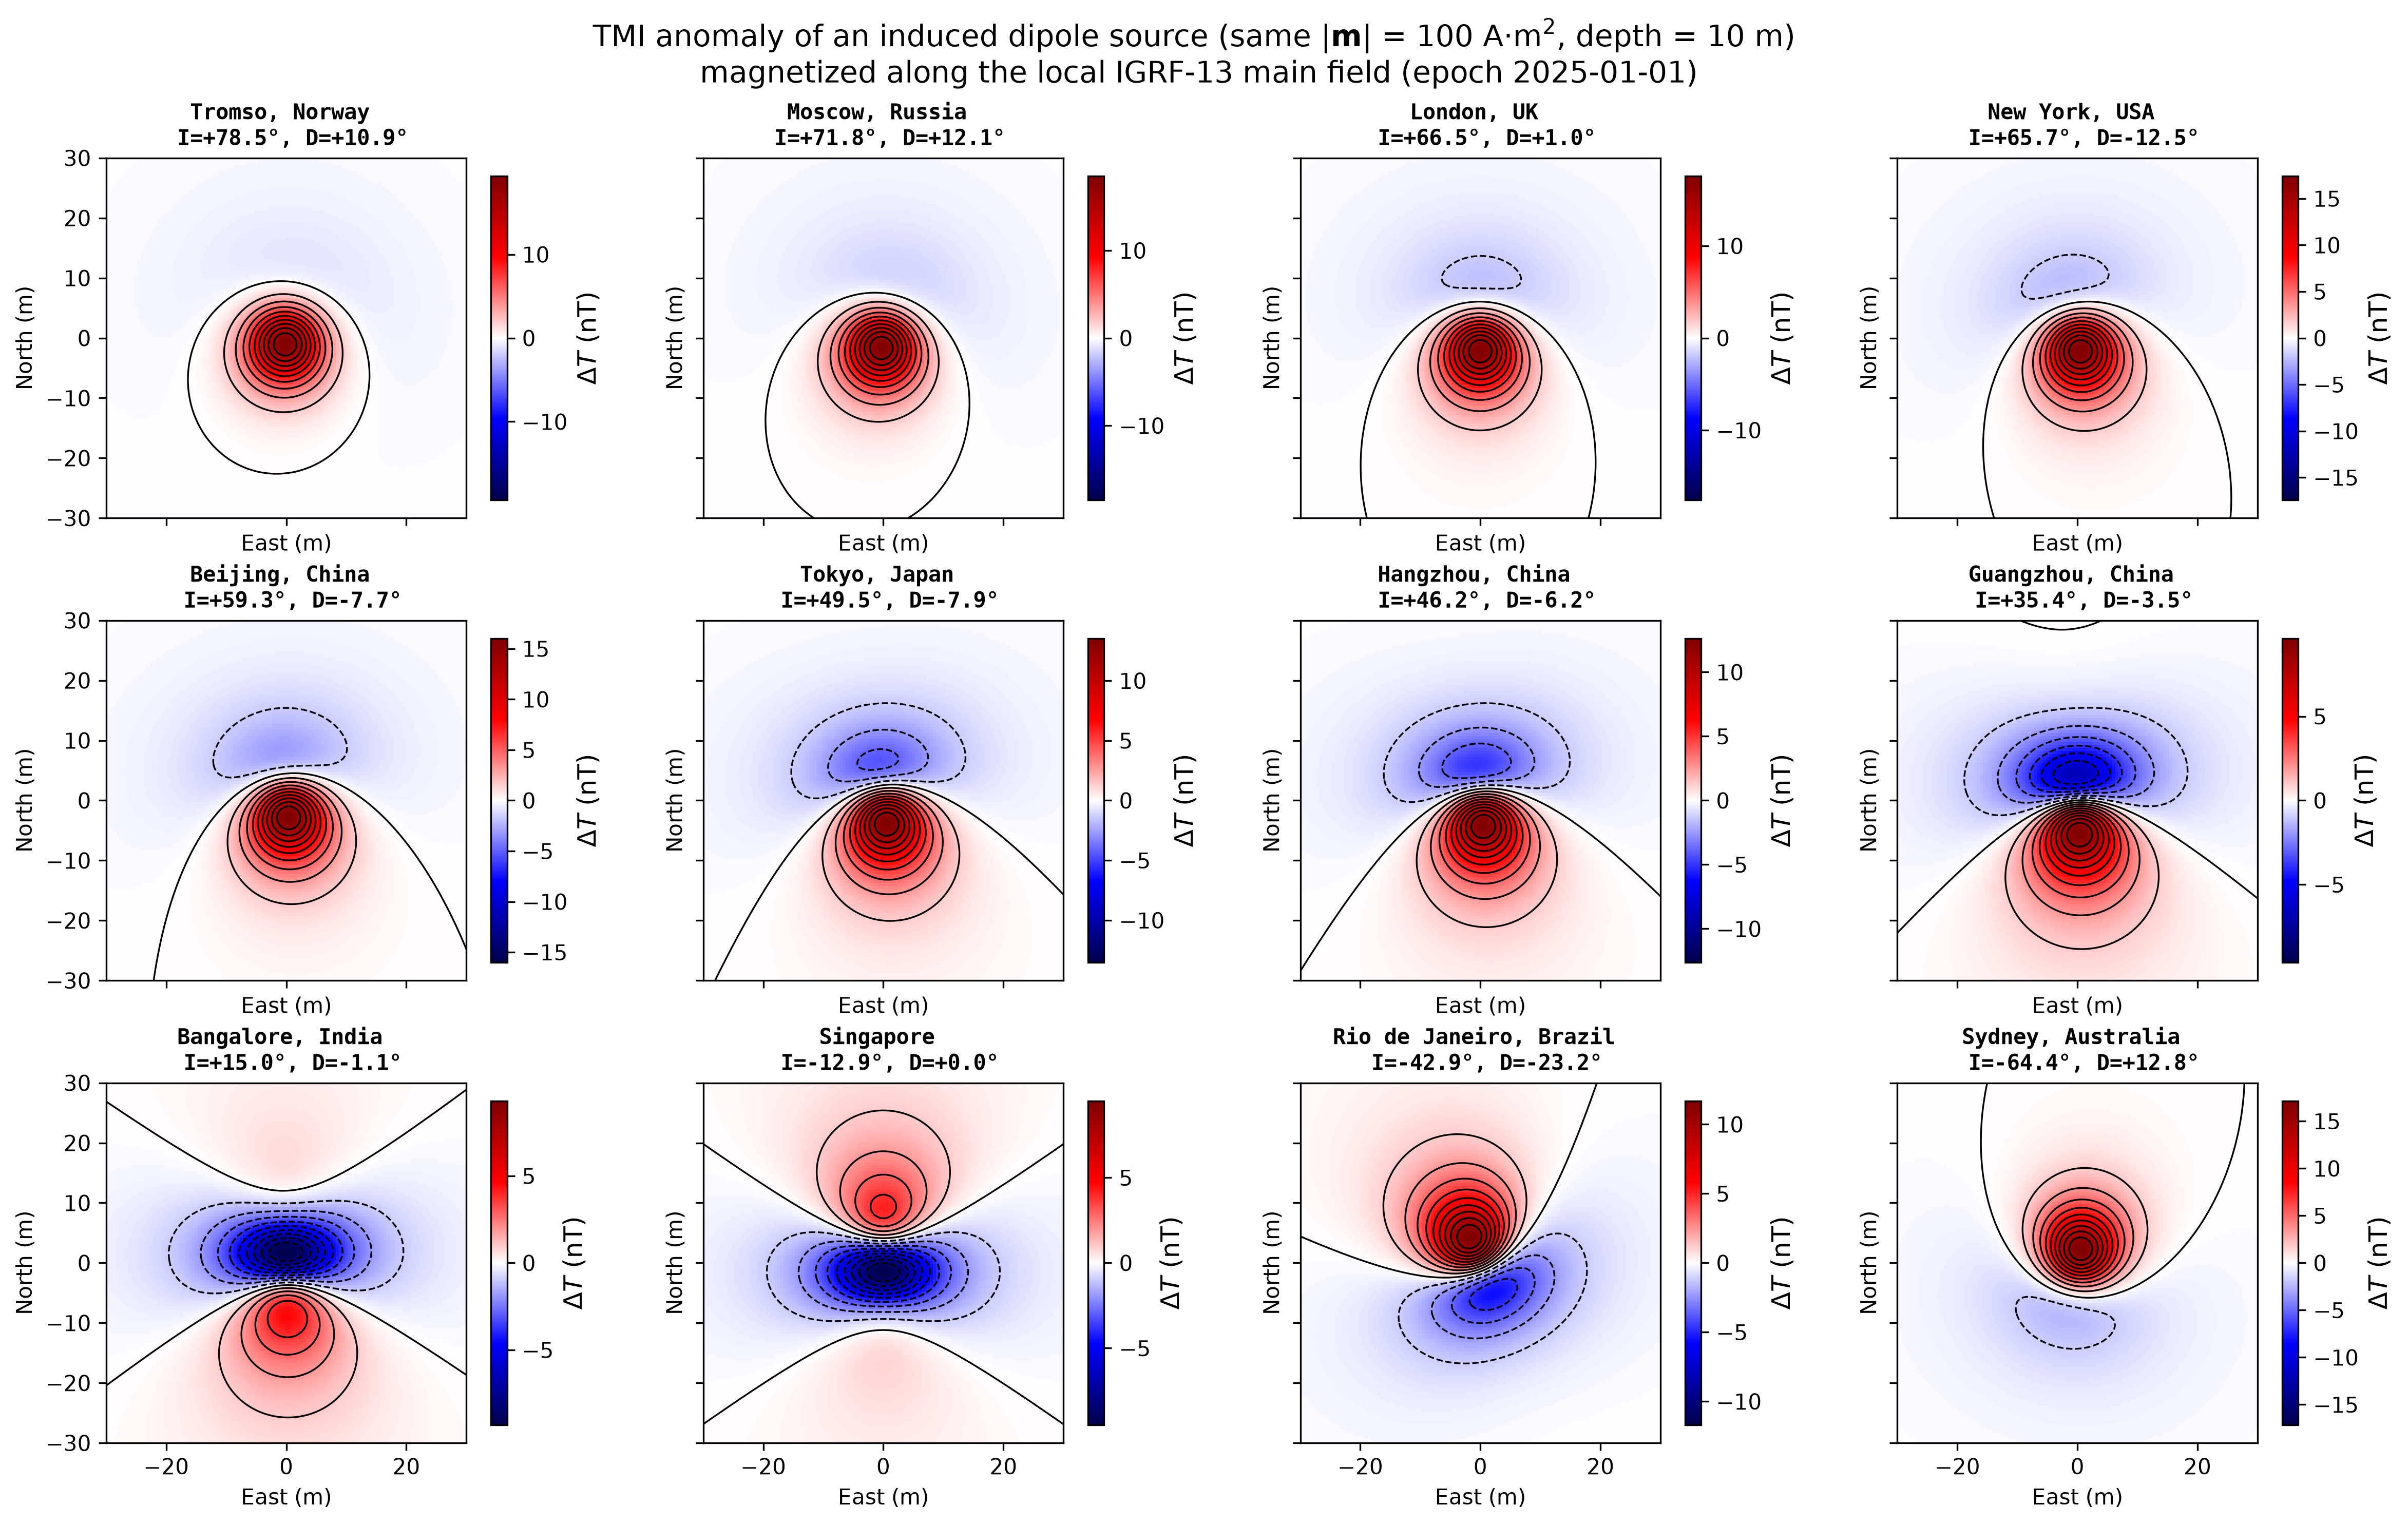

In [4]:
# # ! TMI anomaly maps (induced magnetization: m parallel to local main field)
fig, axes = plt.subplots(3, 4, figsize=(16, 10),
                         sharex=True, sharey=True)
axes = axes.ravel()

for idx, (name, (lat, lon, dec, inc)) in enumerate(POIS.items()):
    ax = axes[idx]

    # TMI anomaly: induced dipole moment aligned with the background field
    tmi = dipole_tmi(obs_ned_f, M, inc, dec, pos_M, inc, dec)

    TMI = tmi.reshape((Nest, Nnor))
    tmi_max = np.abs(tmi).max()

    # Colormesh
    pcm = ax.pcolormesh(
        ESTF, NORF, TMI,
        cmap='seismic',
        vmin=-tmi_max, vmax=tmi_max,
        shading='auto'
    )

    # Contours
    ax.contour(
        ESTF, NORF, TMI,
        levels=np.linspace(-tmi_max, tmi_max, 21),
        colors='black', linewidths=0.8
    )

    # Labeling
    ax.set_title(f"{name} \n I={inc:+.1f}\u00b0, D={dec:+.1f}\u00b0",
                 fontsize=10, fontweight='bold', loc='center', fontfamily='monospace')
    ax.set_xlabel('East (m)')
    ax.set_ylabel('North (m)')
    ax.set_aspect('equal')
    ax.set_xlim(est_1, est_2)
    ax.set_ylim(nor_1, nor_2)

    # Colorbar per subplot
    cbar = fig.colorbar(pcm, ax=ax, orientation='vertical',
                        shrink=0.9, pad=0.05)
    cbar.set_label(r'$\Delta T$ (nT)', fontsize=12)
    cbar.ax.tick_params(labelsize=10)

fig.suptitle('TMI anomaly of an induced dipole source '
             r'(same $|\mathbf{m}|$ = 100 A$\cdot$m$^{2}$, depth = 10 m)'
             '\n magnetized along the local IGRF-13 main field (epoch 2025-01-01)',
             fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 1])
plt.savefig('tmi_poi.png', dpi=300, bbox_inches='tight')
plt.show()